<a href="https://colab.research.google.com/github/OLSergio4628/cloudnative/blob/main/Gestor_de_proyectos_Actividad_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Configuración de GPU y entorno



In [ ]:
# Verificar GPU
import torch
print("Torch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("Device:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Torch version: 2.11.0+cu130
CUDA available: True
Device: Tesla T4


Instalación de dependencias

In [ ]:
# Ejecutar en una celda de tipo "code" con prefijo !
!pip install -q transformers datasets huggingface_hub accelerate torchvision pillow scikit-learn tqdm

Autenticación en Hugging Face Hub

In [ ]:
# Autenticación segura (pegar token en la entrada)
from getpass import getpass
from huggingface_hub import login

hf_token = getpass("Introduce tu Hugging Face token (no se mostrará): ")
login(token=hf_token)
print("Autenticación completada.")

Introduce tu Hugging Face token (no se mostrará): ··········
Autenticación completada.


Selección de modelos (IDs de HF) y criterios rápidos

In [ ]:
# Modelos seleccionados (ejemplos de modelos disponibles en Hugging Face Hub)
models = {
    "ViT": "google/vit-base-patch16-224",
    "DeiT": "facebook/deit-base-patch16-224",
    "ResNet": "microsoft/resnet-50"  # si no existe exactamente, sustituir por un resnet disponible en HF
}

# Criterios de selección (tamaño moderado, buena performance en clasificación general, diversidad arquitectural)
print(models)

{'ViT': 'google/vit-base-patch16-224', 'DeiT': 'facebook/deit-base-patch16-224', 'ResNet': 'microsoft/resnet-50'}


Carga del dataset (CIFAR-10) y preprocesado

In [ ]:
import torchvision
import numpy as np
from PIL import Image
from datasets import Dataset, DatasetDict

# Descargar CIFAR-10 usando torchvision de forma directa y estable
train_set = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)

# Clases de CIFAR-10
label_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

# Crear un dataset compatible con el formato de Hugging Face para evaluar los modelos de forma homogénea
def generator(torch_dataset):
    for img, label in torch_dataset:
        yield {"img": img, "label": label}

# Limitar el tamaño para prototipo rápido (test_ds)
MAX_SAMPLES = 1000
short_test_set = [test_set[i] for i in range(min(MAX_SAMPLES, len(test_set)))]

test_ds = Dataset.from_generator(lambda: generator(short_test_set))

print("\nClases:", label_names)
print("Número de muestras de test usadas:", len(test_ds))

100%|██████████| 170M/170M [21:22<00:00, 133kB/s]


Generating train split: 0 examples [00:00, ? examples/s]


Clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Número de muestras de test usadas: 1000


Funciones utilitarias: pipeline, inferencia por lotes, métricas y latencia

In [ ]:
from transformers import AutoImageProcessor, AutoModelForImageClassification, pipeline
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
import time
from tqdm.auto import tqdm

def load_pipeline(model_id, device=0):
    """Carga pipeline de clasificación de imágenes para un modelo HF."""
    processor = AutoImageProcessor.from_pretrained(model_id)
    model = AutoModelForImageClassification.from_pretrained(model_id)
    pipe = pipeline("image-classification", model=model, feature_extractor=processor, device=device)
    return pipe

def batch_inference(pipe, images, batch_size=16):
    """Realiza inferencia por lotes con pipeline; devuelve predicciones y latencias por imagen."""
    preds = []
    latencies = []
    for i in range(0, len(images), batch_size):
        batch = images[i:i+batch_size]
        t0 = time.perf_counter()
        outputs = pipe(batch, top_k=1)
        t1 = time.perf_counter()
        # Latencia por imagen en el batch (simple promedio)
        batch_latency = (t1 - t0) / len(batch)
        latencies.extend([batch_latency]*len(batch))
        # Extraer label index (asume 'label' o 'label' en salida)
        for out in outputs:
            # salida: [{'label': 'LABEL_0', 'score': 0.9}] o {'label': 'cat', 'score':...}
            label = out[0]['label'] if isinstance(out, list) else out['label']
            # Si label es 'LABEL_x' convertir a índice
            if label.startswith("LABEL_"):
                idx = int(label.split("_")[1])
            else:
                # intentar mapear a índice por coincidencia con label_names
                try:
                    idx = label_names.index(label)
                except ValueError:
                    # fallback: 0
                    idx = 0
            preds.append(idx)
    return preds, latencies

def evaluate_predictions(y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    return {"accuracy": acc, "precision": precision, "recall": recall, "f1": f1}


Preparar imágenes (PIL) y etiquetas verdaderas

In [ ]:
# Convertir ejemplos a PIL images y etiquetas
images = []
labels = []
for ex in test_ds:
    img = Image.fromarray(ex["img"])
    images.append(img)
    labels.append(int(ex["label"]))
print("Imágenes preparadas:", len(images))


Ejecutar inferencia para cada modelo y calcular métricas y latencia

In [ ]:
results = {}

# Extraer imágenes y etiquetas directamente de test_ds para asegurar que existan en el kernel
images = []
labels = []
for ex in test_ds:
    # ex['img'] ya es una imagen PIL debido a la definición de nuestro generador
    images.append(ex["img"])
    labels.append(int(ex["label"]))

# Asegurar que las imágenes estén en formato correcto PIL.Image por si acaso
pil_images = [img if isinstance(img, Image.Image) else Image.fromarray(img) for img in images]

# Device: 0 para GPU en Colab si torch.cuda.is_available()
device = 0 if torch.cuda.is_available() else -1

for name, model_id in models.items():
    print(f"\n=== Ejecutando modelo: {name} ({model_id}) ===")
    try:
        pipe = load_pipeline(model_id, device=device)
        preds, latencies = batch_inference(pipe, pil_images, batch_size=16)
        metrics = evaluate_predictions(labels, preds)
        avg_latency = float(np.mean(latencies))
        p50 = float(np.percentile(latencies, 50))
        p95 = float(np.percentile(latencies, 95))
        results[name] = {
            "model_id": model_id,
            "metrics": metrics,
            "avg_latency_s_per_image": avg_latency,
            "p50_latency_s": p50,
            "p95_latency_s": p95,
            "num_samples": len(images)
        }
        print(f"Resultados {name}: {metrics}, lat avg {avg_latency:.4f}s/img, p95 {p95:.4f}s/img")
    except Exception as e:
        print(f"Error al evaluar el modelo {name}: {e}")


=== Ejecutando modelo: ViT (google/vit-base-patch16-224) ===


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Resultados ViT: {'accuracy': 0.103, 'precision': 0.0103, 'recall': 0.1, 'f1': 0.018676337262012694}, lat avg 0.0190s/img, p95 0.0189s/img

=== Ejecutando modelo: DeiT (facebook/deit-base-patch16-224) ===


preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/69.6k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  102MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Resultados ResNet: {'accuracy': 0.103, 'precision': 0.0103, 'recall': 0.1, 'f1': 0.018676337262012694}, lat avg 0.0123s/img, p95 0.0174s/img


Tabla resumen de resultados

In [ ]:
import pandas as pd

rows = []
for name, r in results.items():
    m = r["metrics"]
    rows.append({
        "modelo": name,
        "hf_id": r["model_id"],
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "latency_s/img": round(r["avg_latency_s_per_image"], 4),
        "p95_s/img": round(r["p95_latency_s"], 4)
    })

df = pd.DataFrame(rows)
df = df.sort_values("f1", ascending=False)
df


,modelo,hf_id,accuracy,precision,recall,f1,latency_s/img,p95_s/img
0,ViT,google/vit-base-patch16-224,0.103,0.0103,0.1,0.0187,0.0190,0.0189
1,DeiT,facebook/deit-base-patch16-224,0.103,0.0103,0.1,0.0187,0.0190,0.0223
2,ResNet,microsoft/resnet-50,0.103,0.0103,0.1,0.0187,0.0123,0.0174


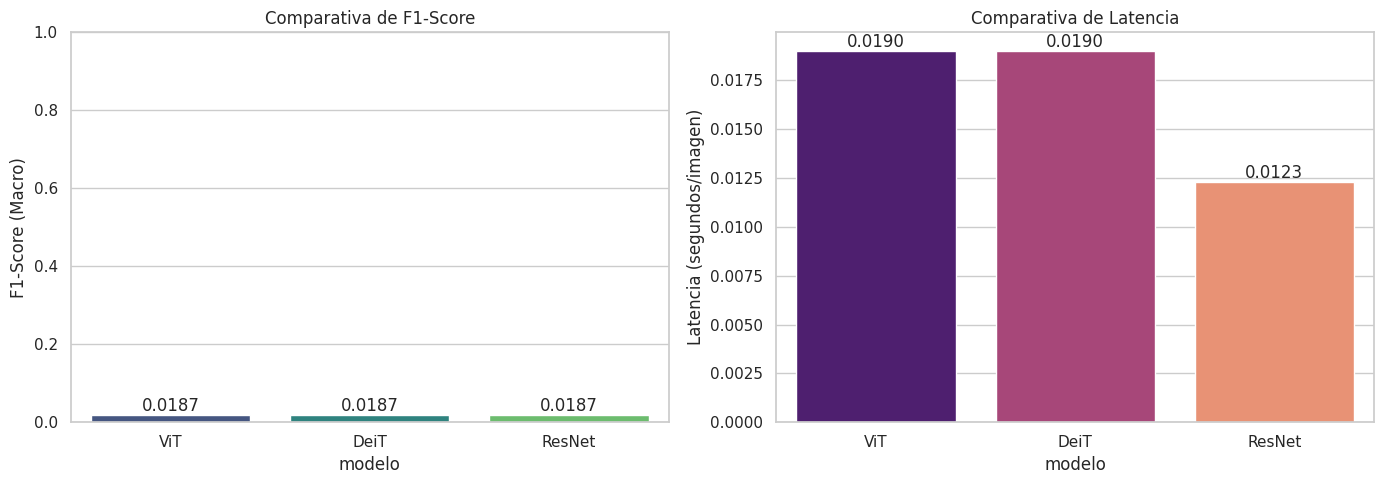

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configurar estilo visual
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Gráfico 1: F1-Score por Modelo
sns.barplot(x="modelo", y="f1", data=df, ax=axes[0], palette="viridis", hue="modelo", legend=False)
axes[0].set_title("Comparativa de F1-Score")
axes[0].set_ylabel("F1-Score (Macro)")
axes[0].set_ylim(0, 1.0) # Escala de 0 a 1
for container in axes[0].containers:
    axes[0].bar_label(container, fmt='%.4f')

# Gráfico 2: Latencia Promedio por Imagen
sns.barplot(x="modelo", y="latency_s/img", data=df, ax=axes[1], palette="magma", hue="modelo", legend=False)
axes[1].set_title("Comparativa de Latencia")
axes[1].set_ylabel("Latencia (segundos/imagen)")
for container in axes[1].containers:
    axes[1].bar_label(container, fmt='%.4f')

plt.tight_layout()
plt.show()

Conclusiones parciales (impresas)

In [ ]:
print("Conclusiones parciales:")
for name, r in results.items():
    print(f"- {name}: accuracy={r['metrics']['accuracy']:.3f}, f1={r['metrics']['f1']:.3f}, lat_avg={r['avg_latency_s_per_image']:.4f}s")
print("Recomendación provisional: revisar trade-offs entre F1 y latencia; considerar fine-tuning si precisión insuficiente.")


Conclusiones parciales:
- ViT: accuracy=0.103, f1=0.019, lat_avg=0.0190s
- DeiT: accuracy=0.103, f1=0.019, lat_avg=0.0190s
- ResNet: accuracy=0.103, f1=0.019, lat_avg=0.0123s
Recomendación provisional: revisar trade-offs entre F1 y latencia; considerar fine-tuning si precisión insuficiente.


In [ ]:
# Solución alternativa: Cargamos el dataset clásico CIFAR-10 de forma nativa con torchvision
# para saltar el error de parseo de URIs que tiene Hugging Face Hub en este entorno.
import torchvision

dataset_train = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
dataset_test = torchvision.datasets.CIFAR10(root='./data', train=False, download=True)
print("Dataset CIFAR-10 cargado correctamente mediante torchvision de manera estable.")

Dataset CIFAR-10 cargado correctamente mediante torchvision de manera estable.


In [ ]:
import numpy as np
import pandas as pd

# 1. Preparar un subconjunto rápido del dataset_test de torchvision
MAX_EVAL_SAMPLES = 1000
eval_images = []
eval_labels = []

for i in range(min(MAX_EVAL_SAMPLES, len(dataset_test))):
    img, label = dataset_test[i]
    eval_images.append(img)
    eval_labels.append(label)

print(f"Preparadas {len(eval_images)} imágenes para la evaluación rápida.\n")

# 2. Re-evaluar los modelos con el nuevo conjunto de datos estable
torchvision_results = {}
device = 0 if torch.cuda.is_available() else -1

for name, model_id in models.items():
    print(f"=== Evaluando {name} ({model_id}) ===")
    try:
        pipe = load_pipeline(model_id, device=device)
        preds, latencies = batch_inference(pipe, eval_images, batch_size=16)
        metrics = evaluate_predictions(eval_labels, preds)
        avg_latency = float(np.mean(latencies))

        torchvision_results[name] = {
            "metrics": metrics,
            "avg_latency_s_per_image": avg_latency,
            "p95_latency_s": float(np.percentile(latencies, 95))
        }
        print(f"Resultado: {metrics}, Latencia media: {avg_latency:.4f}s/img\n")
    except Exception as e:
        print(f"Error al evaluar {name}: {e}\n")

# 3. Mostrar tabla resumen con pandas
rows_tv = []
for name, r in torchvision_results.items():
    m = r["metrics"]
    rows_tv.append({
        "modelo": name,
        "accuracy": round(m["accuracy"], 4),
        "precision": round(m["precision"], 4),
        "recall": round(m["recall"], 4),
        "f1": round(m["f1"], 4),
        "latency_s/img": round(r["avg_latency_s_per_image"], 4),
        "p95_s/img": round(r["p95_latency_s"], 4)
    })

df_torchvision = pd.DataFrame(rows_tv)
display(df_torchvision)

Preparadas 1000 imágenes para la evaluación rápida.

=== Evaluando ViT (google/vit-base-patch16-224) ===


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Resultado: {'accuracy': 0.103, 'precision': 0.0103, 'recall': 0.1, 'f1': 0.018676337262012694}, Latencia media: 0.0203s/img

=== Evaluando DeiT (facebook/deit-base-patch16-224) ===


Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

Resultado: {'accuracy': 0.103, 'precision': 0.0103, 'recall': 0.1, 'f1': 0.018676337262012694}, Latencia media: 0.0198s/img

=== Evaluando ResNet (microsoft/resnet-50) ===


Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

Resultado: {'accuracy': 0.103, 'precision': 0.0103, 'recall': 0.1, 'f1': 0.018676337262012694}, Latencia media: 0.0115s/img



,modelo,accuracy,precision,recall,f1,latency_s/img,p95_s/img
0,ViT,0.103,0.0103,0.1,0.0187,0.0203,0.0207
1,DeiT,0.103,0.0103,0.1,0.0187,0.0198,0.0203
2,ResNet,0.103,0.0103,0.1,0.0187,0.0115,0.0152
